<a href="https://colab.research.google.com/github/MBeckyAlek/Formative3_ML_C1/blob/alec-branch/Formative3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime
import os
import re

In [23]:

df = pd.read_csv("GaltonFamilies.csv")
heights = np.concatenate([df["father"].dropna(), df["childHeight"].dropna()]).astype(float)

np.random.seed(42)
np.random.shuffle(heights)

print("Total heights:", len(heights))
print("First five heights:", heights[:5])

Total heights: 1868
First five heights: [70.2 62.  64.  70.  69. ]


In [19]:
def gaussian_pdf(x, mu, sigma2):
    sigma2 = max(float(sigma2), 1e-8)
    return (1 / np.sqrt(2 * np.pi * sigma2)) * np.exp(-((x - mu) ** 2) / (2 * sigma2))


def initialise_gmm(heights):
    return np.min(heights) + 5, np.max(heights) - 5, 10.0, 10.0, 0.5, 0.5

In [24]:
def expectation_step(heights, mu1, mu2, sigma1_2, sigma2_2, pi1, pi2):
    weighted1 = pi1 * gaussian_pdf(heights, mu1, sigma1_2)
    weighted2 = pi2 * gaussian_pdf(heights, mu2, sigma2_2)
    total = np.maximum(weighted1 + weighted2, 1e-300)

    resp1, resp2 = weighted1 / total, weighted2 / total
    log_likelihood = np.sum(np.log(total))

    return resp1, resp2, log_likelihood


def maximisation_step(heights, resp1, resp2):
    N = len(heights)
    N1, N2 = np.sum(resp1), np.sum(resp2)

    mu1 = np.sum(resp1 * heights) / N1
    mu2 = np.sum(resp2 * heights) / N2

    sigma1_2 = max(np.sum(resp1 * (heights - mu1) ** 2) / N1, 1e-8)
    sigma2_2 = max(np.sum(resp2 * (heights - mu2) ** 2) / N2, 1e-8)

    pi1, pi2 = N1 / N, N2 / N

    return mu1, mu2, sigma1_2, sigma2_2, pi1, pi2

In [25]:
def run_em(heights, num_iterations=10):
    mu1, mu2, sigma1_2, sigma2_2, pi1, pi2 = initialise_gmm(heights)
    history = []

    for i in range(num_iterations + 1):
        resp1, resp2, ll = expectation_step(heights, mu1, mu2, sigma1_2, sigma2_2, pi1, pi2)

        history.append([i, mu1, mu2, sigma1_2, sigma2_2, pi1, pi2, ll])

        if i == num_iterations:
            break

        mu1, mu2, sigma1_2, sigma2_2, pi1, pi2 = maximisation_step(heights, resp1, resp2)

    columns = ["Iteration", "mu1", "mu2", "sigma1_squared", "sigma2_squared", "pi1", "pi2", "Log-Likelihood"]
    return pd.DataFrame(history, columns=columns), {
        "mu1": mu1, "mu2": mu2,
        "sigma1_squared": sigma1_2, "sigma2_squared": sigma2_2,
        "pi1": pi1, "pi2": pi2
    }


tracking_df, final_params = run_em(heights, 10)

display(tracking_df.head(3).round(4))

,Iteration,mu1,mu2,sigma1_squared,sigma2_squared,pi1,pi2,Log-Likelihood
0,0,61.0000,74.0000,10.0000,10.0000,0.5000,0.5000,-6587.6560
1,1,65.0250,70.1111,5.4653,4.0748,0.4207,0.5793,-4876.6361
2,2,65.0768,70.0228,5.9604,4.3637,0.4147,0.5853,-4869.7341


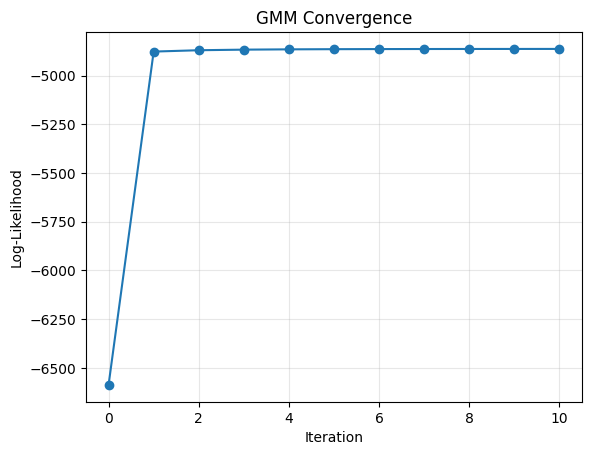

In [26]:
plt.plot(tracking_df["Iteration"], tracking_df["Log-Likelihood"], marker="o")
plt.xlabel("Iteration")
plt.ylabel("Log-Likelihood")
plt.title("GMM Convergence")
plt.grid(True, alpha=0.3)
plt.show()

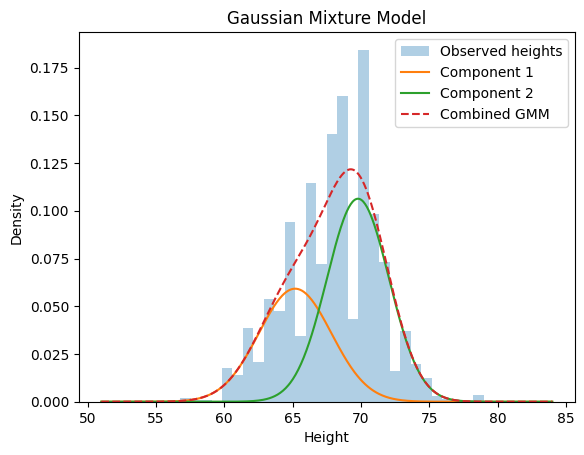

In [27]:
x = np.linspace(heights.min() - 5, heights.max() + 5, 500)

p1 = final_params["pi1"] * gaussian_pdf(x, final_params["mu1"], final_params["sigma1_squared"])
p2 = final_params["pi2"] * gaussian_pdf(x, final_params["mu2"], final_params["sigma2_squared"])

plt.hist(heights, bins=30, density=True, alpha=0.35, label="Observed heights")
plt.plot(x, p1, label="Component 1")
plt.plot(x, p2, label="Component 2")
plt.plot(x, p1 + p2, "--", label="Combined GMM")
plt.xlabel("Height")
plt.ylabel("Density")
plt.title("Gaussian Mixture Model")
plt.legend()
plt.show()

In [48]:
def classify_height(height):
    mu1, mu2 = final_params["mu1"], final_params["mu2"]
    var1, var2 = final_params["sigma1_squared"], final_params["sigma2_squared"]
    pi1, pi2 = final_params["pi1"], final_params["pi2"]

    log_p1 = np.log(pi1) - 0.5 * np.log(2 * np.pi * var1) - ((height - mu1) ** 2) / (2 * var1)
    log_p2 = np.log(pi2) - 0.5 * np.log(2 * np.pi * var2) - ((height - mu2) ** 2) / (2 * var2)

    # Convert log values into stable probabilities
    largest = max(log_p1, log_p2)
    p1 = np.exp(log_p1 - largest)
    p2 = np.exp(log_p2 - largest)
    total = p1 + p2

    print(f"Probability of Component 1: {p1 / total:.4%}")
    print(f"Probability of Component 2: {p2 / total:.4%}")



classify_height(75)  # Replace with the height your coach gives you

Probability of Component 1: 0.8190%
Probability of Component 2: 99.1810%


In [49]:

print("Mean 1:", final_params["mu1"])
print("Mean 2:", final_params["mu2"])
print("Variance 1:", final_params["sigma1_squared"])
print("Variance 2:", final_params["sigma2_squared"])
print("Proportion 1:", final_params["pi1"])
print("Proportion 2:", final_params["pi2"])

print("\nMinimum height:", heights.min())
print("Maximum height:", heights.max())
print("Mean height:", heights.mean())


Mean 1: 65.18286779005113
Mean 2: 69.78351572193903
Variance 1: 7.0443418238980104
Variance 2: 5.174411292212791
Proportion 1: 0.39385656241316847
Proportion 2: 0.6061434375868316

Minimum height: 56.0
Maximum height: 79.0
Mean height: 67.97152034261241


In [45]:
print("Minimum height:", heights.min())
print("Maximum height:", heights.max())
print("Mean height:", heights.mean())

Minimum height: 56.0
Maximum height: 79.0
Mean height: 67.97152034261241


### Part 2: Bayesian Probability

0. Load the dataset and count the number of reviews

In [ ]:
import csv

# Read the dataset robustly handling potential quoting issues
data = pd.read_csv("IMDB Dataset.csv", engine="python", on_bad_lines="skip")
total_reviews = len(data)
print(data.head())
print("reviews:", total_reviews)
print(data["sentiment"].value_counts())

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
reviews: 6270
sentiment
negative    3159
positive    3111
Name: count, dtype: int64


1. Key Word Selection

In [ ]:

# Define positive and negative keywords

positive_words = ["fantastic", "wonderful", "stunning", "best"]
negative_words = ["bad", "boring", "awful", "worst"]

print("Positive keywords:", positive_words)
print("Negative keywords:", negative_words)


Positive keywords: ['fantastic', 'wonderful', 'stunning', 'best']
Negative keywords: ['bad', 'boring', 'awful', 'worst']


2. Choice of Conditional Probability:

We calculate the ratio of how many times the selected key words appeared on each sentiment lqabeld as postive agains negtaibve and vice versa, this to help us with the choice of the conditional probability and in this case we went with P(Positive)

In [ ]:

# Store the counts for each keyword
keyword_counts = {}

# Combine both keyword lists
all_words = positive_words + negative_words

for word in all_words:
    # Find reviews containing this word
    contains_word = data["review"].str.contains(
        r"\b" + re.escape(word) + r"\b",
        case=False,
        na=False
    )

    # Count reviews containing the word for each sentiment
    positive_count = ((data["sentiment"] == "positive") & contains_word).sum()
    negative_count = ((data["sentiment"] == "negative") & contains_word).sum()

    keyword_counts[word] = {
        "positive": positive_count,
        "negative": negative_count
    }

# Display the results
for word, counts in keyword_counts.items():
    print(
        f"{word}: Positive = {counts['positive']}, "
        f"Negative = {counts['negative']}"
    )


fantastic: Positive = 138, Negative = 29
wonderful: Positive = 317, Negative = 66
stunning: Positive = 72, Negative = 20
best: Positive = 768, Negative = 423
bad: Positive = 352, Negative = 1127
boring: Positive = 69, Negative = 320
awful: Positive = 35, Negative = 338
worst: Positive = 53, Negative = 481


3. Computation and Presentation

For each chosen keyword, create a small table or markdown block showing the following probabilities:


In [ ]:
keywords = positive_words

# Prepare the review text and sentiment columns
review_text = data["review"].fillna("").str.lower()
sentiment = data["sentiment"].str.lower()

# 1. Prior
total_reviews = len(data)
positive_total = (sentiment == "positive").sum()
p_positive = positive_total / total_reviews

results = []

for keyword in keywords:

    # Find reviews containing the keyword
    contains_keyword = review_text.str.contains(
        r"\b" + re.escape(keyword) + r"\b",
        regex=True,
        na=False
    )

    all_with_keyword = contains_keyword.sum()

    positive_with_keyword = (
        (sentiment == "positive") & contains_keyword
    ).sum()

    # 2. Likelihood
    likelihood = positive_with_keyword / positive_total

    # 3. Marginal
    marginal = all_with_keyword / total_reviews

    # 4. Posterior
    if marginal > 0:
        posterior = (likelihood * p_positive) / marginal
    else:
        posterior = None

    results.append({
        "Keyword": keyword,
        "Prior P(Positive)": p_positive,
        "Likelihood P(keyword|Positive)": likelihood,
        "Marginal P(keyword)": marginal,
        "Posterior P(Positive|keyword)": posterior
    })

# Display the results
results_df = pd.DataFrame(results)
display(results_df.round(4))


,Keyword,Prior P(Positive),Likelihood P(keyword|Positive),Marginal P(keyword),Posterior P(Positive|keyword)
0,fantastic,0.4962,0.0444,0.0266,0.8263
1,wonderful,0.4962,0.1019,0.0611,0.8277
2,stunning,0.4962,0.0231,0.0147,0.7826
3,best,0.4962,0.2469,0.1900,0.6448


# Part 4: Gradient descent

In [ ]:
rng = np.random.default_rng(seed=42)

w = np.array([-1, 2]).reshape(-1, 1)
# b = np.array([1]).reshape(-1, 1)
b = np.float64(1)
alpha = 0.01

data = pd.DataFrame({
    "y": [5, 6],
    "x_i1": [1, 4],
    "x_i2": [3, 10]
})

data, w.shape, b.shape

(   y  x_i1  x_i2
 0  5     1     3
 1  6     4    10,
 (2, 1),
 ())

In [ ]:
X = data.copy().drop(columns=['y']).to_numpy()
y = data.copy()['y'].to_numpy().reshape(-1, 1)

X.shape, y.shape

((2, 2), (2, 1))

In [ ]:
def numerical_derivative(loss, x, *args, eps=1e-7):
    """
    Numerical derivative of any scalar loss(x, *args) with respect to x
    """
    x = np.asarray(x, dtype=float)
    grad = approx_fprime(
        x.ravel(),
        lambda v, *a: loss(v.reshape(x.shape), *a),
        eps,
        *args
    )
    return grad.reshape(x.shape)

In [ ]:
def forward_propagation(weights, bias, X):
    return X @ weights + bias

def mean_squared_error(y_actual, y_pred):
    return np.mean((y_actual - y_pred) ** 2)

def mse_derivative_scipy(y_actual, y_pred):
    return numerical_derivative(
        lambda p, y_a: mean_squared_error(y_a, p),
        y_pred,
        y_actual
    )

def params_gradient(w, b, X, y, eps=1e-7):
    theta = np.append(w.ravel(), b)

    def loss(t, X, y):
        w_ = t[:-1].reshape(-1, 1)
        b_ = t[-1]
        return mean_squared_error(y, forward_propagation(w_, b_, X))

    g = approx_fprime(theta, loss, eps, X, y)

    dw = g[:-1].reshape(-1, 1)
    db = g[-1]
    return dw, db

def update_params(w, b, dw, db, alpha):
    w = w - (alpha * dw)
    b = b - (alpha * db)
    return w, b

In [ ]:
for i in range(3):
    y_pred = forward_propagation(w, b, X)
    mse = mean_squared_error(y, y_pred)
    gradient = mse_derivative_scipy(y, y_pred)
    dw, db = params_gradient(w, b, X, y)
    w, b = update_params(w, b, dw, db, alpha)

    print(f"iteration: {i}")
    print("MSE:", mse)
    print("w:", w)
    print("b:", b)
    print("----------------")

iteration: 0
MSE: 61.0
w: [[-1.45000001]
 [ 0.86999995]]
b: 0.8799999972466469
----------------
iteration: 1
MSE: 6.845001798636092
w: [[-1.33159999]
 [ 1.18079996]]
b: 0.9318000038691272
----------------
iteration: 2
MSE: 2.7238167970586282
w: [[-1.36956198]
 [ 1.09518195]]
b: 0.9362400082356344
----------------
